# 002594 比亚迪 — 均线探索：降回撤 / 稳收益候选方案

**目的**：仿 `crypto_contract_signal_explorer.ipynb` 的做法，把 BTC 上已验证的"均线门控"思路（gate_only / V1 双均线）搬到 002594 的日线上**先看形状**：哪些均线 / 动量指标规则在比亚迪身上能减少回撤、收益代价多大。**本 notebook 不出 PASS/FAIL**；任何候选要变成假设，按 §7 登记后再进正式回测器。

**数据**（`192.168.1.68/ginkgo_bole`）：
- `cnstock_kline_day` 002594：2011-06-30 → 2026-09-28，3702 个交易日，**已前复权**；停牌仅 12 天（多在 2015）
- 参照：沪深300（`000300`）、SW 汽车（`801880`，2014-02 起）

**口径**（与 `scripts/cn_backtest_gate.py` 一致）：
- T 收盘出信号 → **T+1 生效**（吃 T+1 的 close-to-close 收益），无未来函数
- 成本按 §1.2：买入 0.125%，卖出 0.125% + 印花税（2023-08-28 起 0.1% → 0.05%），切换日计费
- 跌停开盘 / 停牌日**卖出顺延**（涨停开盘买入顺延）；用 `close.shift(1)` 判涨跌停，规避 `pre_close` 字段怪癖（见 `utils/db.py` 警告）
- 分段与 A 股既有研究一致：pre_val 2017–2021 / val 2022–2025-06 / **test 2025-07→**
  ⚠️ test 段已在本 notebook 中展示 ⇒ 看完之后提的任何假设都不再是无偏的，只能算描述

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "utils").is_dir():
    ROOT = ROOT.parent                      # 从 notebooks/ 下启动时
sys.path.insert(0, str(ROOT))

from sqlalchemy import text
from utils.db import read_cnstock_kline_day, get_contract_engine
from strategies.cn_a_trend_base.costs import buy_cost, sell_cost
from strategies.cn_a_trend_base.ew_index import summarize

pd.set_option("display.width", 200)
plt.rcParams["font.family"] = ["Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

EPISODE_COLOR = "rgba(255,0,0,0.10)"
SMA_LIST = [20, 50, 100, 150, 200, 250]
SMA_COLOR = {20: "#1f77b4", 50: "#ff7f0e", 100: "#2ca02c", 150: "#d62728", 200: "#9467bd", 250: "#8c564b"}
SEGMENTS = {"全段(2012-07→)": ("2012-07-01", None),
            "pre_val": ("2017-01-01", "2021-12-31"),
            "val": ("2022-01-01", "2025-06-30"),
            "test": ("2025-07-01", None)}

## 0. 读取与数据快照

002594 日线（前复权）。`trade_time` 存的是交易日前一晚 16:00 UTC（= 交易日 00:00 北京），这里转回**交易日日期**建索引。

In [2]:
raw = read_cnstock_kline_day("002594")
df = raw.rename(columns={"open_price": "open", "high_price": "high",
                         "low_price": "low", "close_price": "close"}).copy()
ts = pd.to_datetime(df["trade_time"])
if ts.dt.tz is None:
    ts = ts.dt.tz_localize("UTC")
df["date"] = ts.dt.tz_convert("Asia/Shanghai").dt.tz_localize(None).dt.normalize()
df = df.set_index("date").sort_index()
assert df.index.is_unique and df.index.is_monotonic_increasing

for n in SMA_LIST:
    df[f"sma{n}"] = df["close"].rolling(n).mean()
df["ret"] = df["close"].pct_change()
df["prev_close"] = df["close"].shift(1)
df["limit_up_open"] = (df["open"] / df["prev_close"] - 1) >= 0.098
df["limit_down_open"] = (df["open"] / df["prev_close"] - 1) <= -0.098

with get_contract_engine().connect() as conn:
    idx300 = pd.read_sql(text("SELECT trade_date, close FROM cnstock_index_kline_day "
                              "WHERE index_code='000300' ORDER BY 1"),
                         conn, parse_dates=["trade_date"], index_col="trade_date")["close"]
    auto = pd.read_sql(text("SELECT trade_date, close FROM cnstock_index_kline_day "
                            "WHERE index_code='801880' ORDER BY 1"),
                       conn, parse_dates=["trade_date"], index_col="trade_date")["close"]
idx300.index = pd.to_datetime(idx300.index).normalize()
auto.index = pd.to_datetime(auto.index).normalize()

print(f"002594 日线：{df.index[0].date()} → {df.index[-1].date()}，{len(df)} 个交易日")
print(f"停牌 {int(df['suspension'].sum())} 天；涨停开盘 {int(df['limit_up_open'].sum())} / 跌停开盘 {int(df['limit_down_open'].sum())} 天")
print(f"沪深300：{idx300.index[0].date()} → {idx300.index[-1].date()}；SW汽车：{auto.index[0].date()} → {auto.index[-1].date()}")

002594 日线：2011-06-30 → 2026-09-29，3703 个交易日
停牌 12 天；涨停开盘 6 / 跌停开盘 5 天
沪深300：2005-01-04 → 2026-09-18；SW汽车：2014-02-21 → 2026-09-21


### 0.1 规则回测器（notebook 内，探索用）

`backtest_signal(sig)`：任意**布尔信号**（T 收盘可知）→ T+1 生效的统一回测；`backtest_ma_rule(df, slow, fast=None)` 是它的均线版包装：
- `fast=None` → 单均线门控：`close > SMA(slow)` → 100%，否则 0%
- 给定 `fast` → 双均线（BTC V1 的 A 股版）：`close > SMA(slow)` 且 `close > SMA(fast)` → 100%，否则 0%
- 跌停开盘 / 停牌日卖出顺延（涨停开盘买入顺延，逐日重试直到成交）
- 返回 `pos / ret_net / idx_net / switch`，顺延次数记在 `attrs`

In [3]:
def backtest_signal(df: pd.DataFrame, sig: pd.Series) -> pd.DataFrame:
    desired = sig.shift(1, fill_value=False).to_numpy(bool)  # T+1 目标仓位

    susp = (df["suspension"].fillna(0) == 1).to_numpy(bool)
    lu = df["limit_up_open"].fillna(False).to_numpy(bool)
    ld = df["limit_down_open"].fillna(False).to_numpy(bool)
    pos = np.zeros(len(df))
    cur, delay_buys, delay_sells = 0.0, 0, 0
    for i in range(len(df)):
        want = desired[i]
        if want != cur:
            if susp[i] or (want and lu[i]) or (not want and ld[i]):
                delay_buys += want
                delay_sells += (not want)
            else:
                cur = 1.0 if want else 0.0
        pos[i] = cur
    pos = pd.Series(pos, index=df.index)

    switch = pos.diff().fillna(pos)
    cost = pd.Series(0.0, index=df.index)
    cost[switch > 0] = buy_cost()
    cost[switch < 0] = [sell_cost(d) for d in switch.index[switch < 0]]
    ret_net = pos * df["ret"].fillna(0.0) - cost
    out = pd.DataFrame({"pos": pos, "ret_net": ret_net, "switch": (switch != 0).astype(int)})
    out["idx_net"] = (1.0 + ret_net).cumprod()
    out.attrs["delay_buys"], out.attrs["delay_sells"] = int(delay_buys), int(delay_sells)
    return out


def backtest_ma_rule(df: pd.DataFrame, slow: int, fast: int | None = None) -> pd.DataFrame:
    sig = df["close"] > df[f"sma{slow}"]
    if fast is not None:
        sig = sig & (df["close"] > df[f"sma{fast}"])
    sig = sig & df[f"sma{slow}"].notna()                     # 预热期 = 空仓
    return backtest_signal(df, sig)


def seg_slice(s: pd.Series, lo: str, hi: str | None) -> pd.Series:
    return s.loc[lo:hi] if hi else s.loc[lo:]


def seg_metrics(r: pd.DataFrame, lo: str, hi: str | None, base: dict) -> dict:
    idx = (1 + seg_slice(r["ret_net"], lo, hi)).cumprod()
    m = summarize(idx)
    years = m["years"] or np.nan
    return {"总收益": m["total_return"], "年化": m["ann_return"], "MDD": m["max_drawdown"],
            "MDD比": abs(m["max_drawdown"] / base["max_drawdown"]),
            "收益比": (m["total_return"] / base["total_return"]) if base["total_return"] > 0 else np.nan,
            "Calmar": m["calmar"], "Sharpe": m["sharpe"],
            "切换/年": seg_slice(r["switch"], lo, hi).sum() / years,
            "持仓占比": seg_slice(r["pos"], lo, hi).mean()}


def bh_frame(ret: pd.Series) -> pd.DataFrame:
    out = pd.DataFrame({"pos": 1.0, "ret_net": ret.fillna(0.0)})
    out["switch"] = 0
    out["idx_net"] = (1 + out["ret_net"]).cumprod()
    return out

BH = bh_frame(df["ret"])          # buy & hold（毛，1 买 1 卖成本可忽略）
print("回测器就绪；基准 = buy&hold 毛收益")

回测器就绪；基准 = buy&hold 毛收益


## 1. 底座与回撤 episode（先看这里）

buy&hold 是唯一的基准。下面标出它最深的 5 段回撤（peak → trough，修复日 end），
后面所有规则的价值都要用"**在这几段里少吃了多少**"来衡量——BTC 的教训是：规则在其它时间的表现基本都是噪音。
两条参照规则：`gate SMA200`（BTC 底座类比）、`dual 200+50`（BTC V1 类比）。

In [4]:
def drawdown_episodes(idx: pd.Series, top: int = 5) -> pd.DataFrame:
    dd = idx / idx.cummax() - 1.0
    eps, in_ep, peak, trough, last_high = [], False, None, None, dd.index[0]
    for d, v in dd.items():
        if v == 0:
            if in_ep:
                eps.append({"peak": peak, "trough": trough, "end": d, "depth": dd[trough],
                            "自然日": (d - peak).days})
                in_ep = False
            last_high = d
        elif not in_ep:
            in_ep, peak, trough = True, last_high, d
        elif v < dd[trough]:
            trough = d
    if in_ep:                                                # 未修复的也记录
        eps.append({"peak": peak, "trough": trough, "end": dd.index[-1], "depth": dd[trough],
                    "自然日": (dd.index[-1] - peak).days})
    return pd.DataFrame(eps).sort_values("depth").head(top).sort_values("peak").reset_index(drop=True)

episodes = drawdown_episodes(BH["idx_net"], top=5)
r_gate200 = backtest_ma_rule(df, 200)
r_dual = backtest_ma_rule(df, 200, 50)
print(episodes.assign(depth=(episodes["depth"] * 100).round(1)).to_string(index=False))

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.65, 0.35],
                    subplot_titles=["净值（log）：buy&hold vs 参照规则", "buy&hold 回撤"])
fig.add_trace(go.Scatter(x=df.index, y=BH["idx_net"], name="buy&hold", line=dict(color="#222", width=1.2)), row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=r_gate200["idx_net"], name="gate SMA200", line=dict(color="#9467bd", width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=r_dual["idx_net"], name="dual 200+50", line=dict(color="#ff7f0e", width=1)), row=1, col=1)
fig.update_yaxes(type="log", row=1, col=1)
dd = BH["idx_net"] / BH["idx_net"].cummax() - 1
fig.add_trace(go.Scatter(x=df.index, y=dd, name="回撤", fill="tozeroy", line=dict(color="#c00", width=1), showlegend=False), row=2, col=1)
for _, e in episodes.iterrows():
    fig.add_vrect(x0=e["peak"], x1=e["trough"], fillcolor=EPISODE_COLOR, line_width=0)
fig.update_layout(height=620, margin=dict(t=40))
fig.show()

      peak     trough        end  depth  自然日
2011-07-07 2012-09-26 2013-05-10  -81.2  673
2014-03-03 2014-12-22 2015-03-05  -46.6  367
2015-06-04 2018-08-06 2020-07-07  -61.7 1860
2021-02-02 2021-05-07 2021-08-02  -47.7  181
2022-06-23 2024-02-02 2025-02-14  -53.7  967


## 2. 全景：价格 × 六条均线（对数轴）+ 参照规则仓位条纹

先看均线和价格的相对关系：比亚迪是**长趋势 + 深回撤**的品种（2011→2026 约 15 倍，但 -50% 以上回撤有好几段），
这类品种门控规则天然有发挥空间——代价是震荡期的来回打脸（切换次数那一列）。

In [5]:
def add_state_strip(fig, ts, pos, row, name):
    fig.add_trace(go.Heatmap(x=ts, y=[name], z=[pos.values], showscale=False, zmin=0, zmax=1,
                             colorscale=[[0, "#f0f0f0"], [1, "#4c9aff"]]), row=row, col=1)

fig = make_subplots(rows=3, cols=1, shared_xaxes=True, row_heights=[0.62, 0.18, 0.20],
                    subplot_titles=["002594 前复权收盘（log）+ 均线", "buy&hold 回撤", "参照规则仓位（蓝=持仓）"])
fig.add_trace(go.Scatter(x=df.index, y=df["close"], name="close", line=dict(color="#222", width=1.2)), row=1, col=1)
for n in SMA_LIST:
    fig.add_trace(go.Scatter(x=df.index, y=df[f"sma{n}"], name=f"SMA{n}",
                             line=dict(color=SMA_COLOR[n], width=1)), row=1, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=dd, fill="tozeroy", line=dict(color="#c00", width=1), showlegend=False), row=2, col=1)
add_state_strip(fig, df.index, r_gate200["pos"], 3, "gate200")
add_state_strip(fig, df.index, r_dual["pos"], 3, "dual200+50")
for _, e in episodes.iterrows():
    fig.add_vrect(x0=e["peak"], x1=e["trough"], fillcolor=EPISODE_COLOR, line_width=0)
fig.update_layout(height=760, margin=dict(t=40))
fig.show()

## 3. 单均线门控网格：gate SMA(N)，N ∈ {20, 50, 100, 150, 200, 250}

`close > SMA(N)` → 100%，否则 0%。**描述性呈现，不出判定**：
- `MDD比` = 规则 MDD / 同期 buy&hold MDD（< 1 才算动了回撤；BTC 的验收线是 ≤ 2/3）
- `收益比` = 规则总收益 / 同期 buy&hold 总收益（门控的成本列；BTC 验收线是 ≥ 80%）
- `切换/年` = 每年买卖次数（A 股一次完整切换 ≈ 0.28% 成本）
- `持仓占比` < 1 说明有相当时间在空仓——空仓期的机会成本已经体现在收益比里

In [6]:
rules1 = {n: backtest_ma_rule(df, n) for n in SMA_LIST}
for n, r in rules1.items():
    if r.attrs["delay_buys"] or r.attrs["delay_sells"]:
        print(f"gate SMA{n}：顺延买入 {r.attrs['delay_buys']} 次 / 顺延卖出 {r.attrs['delay_sells']} 次")

tables1 = {}
for seg_name, (lo, hi) in SEGMENTS.items():
    base = summarize(seg_slice(BH["idx_net"], lo, hi))
    rows = {"buy&hold": {"总收益": base["total_return"], "年化": base["ann_return"],
                        "MDD": base["max_drawdown"], "MDD比": 1.0, "收益比": 1.0,
                        "Calmar": base["calmar"], "Sharpe": base["sharpe"], "切换/年": 0.0, "持仓占比": 1.0}}
    for n, r in rules1.items():
        rows[f"gate SMA{n}"] = seg_metrics(r, lo, hi, base)
    t = pd.DataFrame(rows).T
    tables1[seg_name] = t
    print(f"\n=== {seg_name}（{lo} → {hi or '今'}）===")
    display(t.style.format({"总收益": "{:+.1%}", "年化": "{:+.1%}", "MDD": "{:.1%}",
                            "MDD比": "{:.2f}", "收益比": "{:.2f}", "Calmar": "{:.2f}",
                            "Sharpe": "{:.2f}", "切换/年": "{:.1f}", "持仓占比": "{:.0%}"}))


=== 全段(2012-07→)（2012-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+2178.3%,+24.7%,-61.7%,1.00,1.00,0.40,0.68,0.0,100%
gate SMA20,+548.6%,+14.1%,-60.5%,0.98,0.25,0.23,0.53,28.5,50%
gate SMA50,+847.1%,+17.2%,-57.0%,0.92,0.39,0.30,0.59,16.2,50%
gate SMA100,+694.3%,+15.7%,-61.8%,1.00,0.32,0.25,0.56,10.6,52%
gate SMA150,+315.4%,+10.6%,-84.0%,1.36,0.14,0.13,0.45,10.6,54%
gate SMA200,+416.2%,+12.3%,-78.6%,1.27,0.19,0.16,0.48,8.0,55%
gate SMA250,+284.4%,+10.0%,-82.9%,1.34,0.13,0.12,0.43,7.6,55%



=== pre_val（2017-01-01 → 2021-12-31）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+537.2%,+45.0%,-55.6%,1.00,1.00,0.81,0.99,0.0,100%
gate SMA20,+388.6%,+37.5%,-46.7%,0.84,0.72,0.80,0.98,24.1,53%
gate SMA50,+382.9%,+37.2%,-43.9%,0.79,0.71,0.85,0.95,14.0,56%
gate SMA100,+295.0%,+31.7%,-39.3%,0.71,0.55,0.81,0.85,10.0,58%
gate SMA150,+223.1%,+26.5%,-47.8%,0.86,0.42,0.55,0.75,10.4,59%
gate SMA200,+268.6%,+29.9%,-50.3%,0.90,0.50,0.60,0.81,5.4,60%
gate SMA250,+334.0%,+34.3%,-50.8%,0.91,0.62,0.67,0.88,4.6,61%



=== val（2022-01-01 → 2025-06-30）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+24.8%,+6.6%,-53.7%,1.00,1.00,0.12,0.36,0.0,100%
gate SMA20,-36.8%,-12.5%,-54.6%,1.02,-1.48,-0.23,-0.40,38.3,49%
gate SMA50,-1.5%,-0.4%,-38.2%,0.71,-0.06,-0.01,0.11,18.5,48%
gate SMA100,+32.4%,+8.5%,-39.5%,0.74,1.31,0.21,0.44,7.5,52%
gate SMA150,-14.4%,-4.4%,-51.5%,0.96,-0.58,-0.09,-0.05,10.7,50%
gate SMA200,-4.1%,-1.2%,-40.8%,0.76,-0.16,-0.03,0.08,7.0,49%
gate SMA250,-13.0%,-3.9%,-41.3%,0.77,-0.52,-0.10,-0.02,8.7,47%



=== test（2025-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,-24.8%,-20.6%,-31.4%,1.00,1.00,-0.66,-0.71,0.0,100%
gate SMA20,-24.6%,-20.4%,-28.3%,0.90,nan,-0.72,-1.26,25.9,33%
gate SMA50,-22.0%,-18.2%,-24.2%,0.77,nan,-0.75,-1.16,19.4,33%
gate SMA100,-7.2%,-5.9%,-12.2%,0.39,nan,-0.48,-0.43,4.8,15%
gate SMA150,-19.9%,-16.4%,-19.9%,0.63,nan,-0.82,-1.66,13.7,14%
gate SMA200,-23.8%,-19.7%,-24.5%,0.78,nan,-0.80,-1.73,18.6,17%
gate SMA250,-20.0%,-16.5%,-23.4%,0.74,nan,-0.70,-1.42,12.1,22%


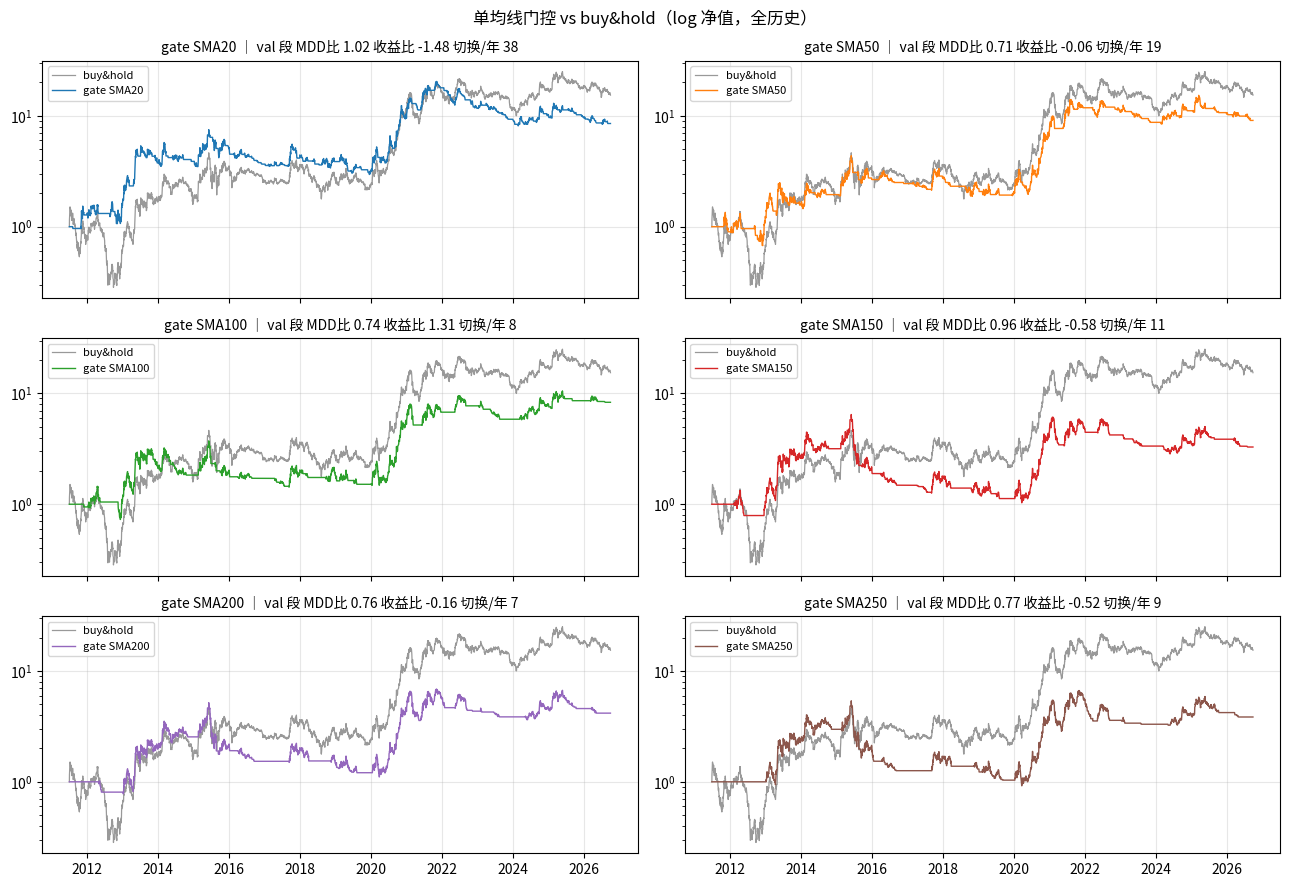

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for ax, n in zip(axes.flat, SMA_LIST):
    r = rules1[n]
    ax.plot(df.index, BH["idx_net"], color="#999", lw=0.9, label="buy&hold")
    ax.plot(df.index, r["idx_net"], color=SMA_COLOR[n], lw=1.0, label=f"gate SMA{n}")
    ax.set_yscale("log")
    v = tables1["val"].loc[f"gate SMA{n}"]
    ax.set_title(f"gate SMA{n} ｜ val 段 MDD比 {v['MDD比']:.2f} 收益比 {v['收益比']:.2f} 切换/年 {v['切换/年']:.0f}",
                 fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.3)
fig.suptitle("单均线门控 vs buy&hold（log 净值，全历史）", fontsize=12)
fig.tight_layout()
plt.show()

## 4. 双均线网格：慢线门 + 快线退出（BTC V1 的 A 股版）

`close > SMA(slow)` 且 `close > SMA(fast)` → 100%，否则 0%；slow ∈ {150, 200, 250} × fast ∈ {20, 50, 100}。
BTC 上这个结构（200+50）是唯一把回撤压到 2/3 以内的规则——机制是**慢线定 regime、快线抢在 regime 恶化初期离场**。
热力图看 val 段（选择段）与全段的 MDD 比 / 收益比：颜色只是相对位置，数字为准。

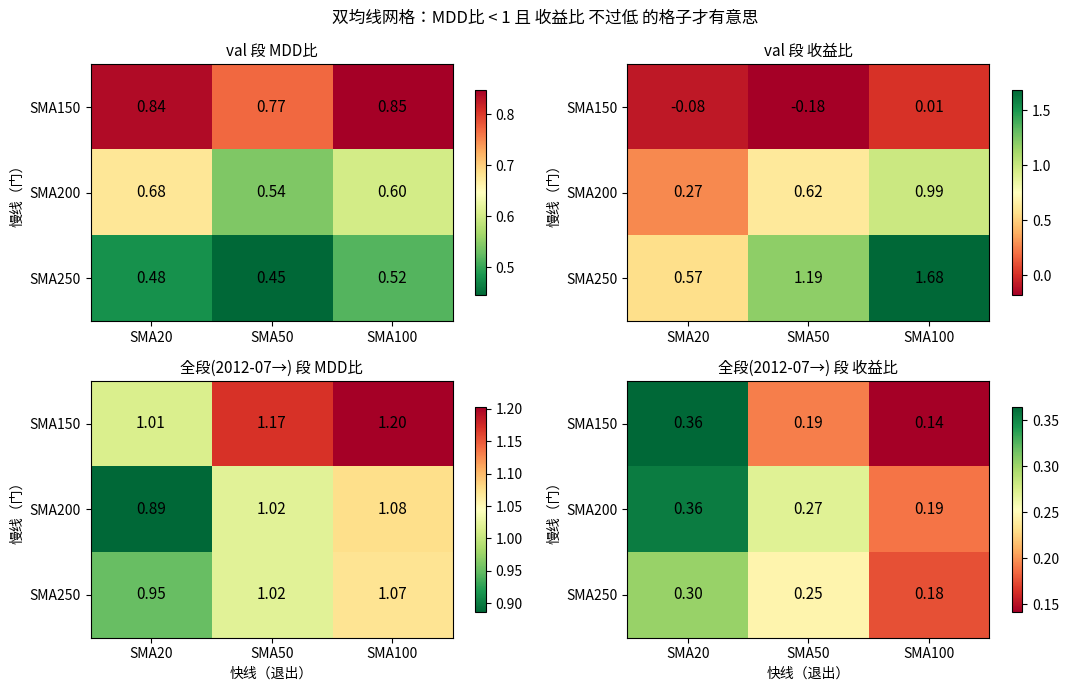

In [8]:
SLOW_LIST, FAST_LIST = [150, 200, 250], [20, 50, 100]
rules2 = {(s, f): backtest_ma_rule(df, s, f) for s in SLOW_LIST for f in FAST_LIST}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (seg_name, col_key, better) in enumerate([("val", "MDD比", "low"), ("val", "收益比", "high"),
                                                 ("全段(2012-07→)", "MDD比", "low"), ("全段(2012-07→)", "收益比", "high")]):
    ax = axes.flat[j]
    lo, hi = SEGMENTS[seg_name]
    base = summarize(seg_slice(BH["idx_net"], lo, hi))
    grid = pd.DataFrame(index=[f"SMA{s}" for s in SLOW_LIST], columns=[f"SMA{f}" for f in FAST_LIST], dtype=float)
    for (s, f_), r in rules2.items():
        grid.loc[f"SMA{s}", f"SMA{f_}"] = seg_metrics(r, lo, hi, base)[col_key]
    im = ax.imshow(grid.values, cmap="RdYlGn_r" if better == "low" else "RdYlGn", aspect="auto")
    ax.set_xticks(range(len(FAST_LIST)), grid.columns)
    ax.set_yticks(range(len(SLOW_LIST)), grid.index)
    ax.set_xlabel("快线（退出）" if j >= 2 else "")
    ax.set_ylabel("慢线（门）")
    for ii in range(grid.shape[0]):
        for jj in range(grid.shape[1]):
            ax.text(jj, ii, f"{grid.values[ii, jj]:.2f}", ha="center", va="center", fontsize=11)
    ax.set_title(f"{seg_name} 段 {col_key}", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("双均线网格：MDD比 < 1 且 收益比 不过低 的格子才有意思", fontsize=12)
fig.tight_layout()
plt.show()

rows = {}
for (s, f_), r in rules2.items():
    for seg_name, (lo, hi) in SEGMENTS.items():
        base = summarize(seg_slice(BH["idx_net"], lo, hi))
        rows[(f"{s}+{f_}", seg_name)] = seg_metrics(r, lo, hi, base)
t2 = pd.DataFrame(rows).T.rename_axis(["规则", "段"])
display(t2.style.format({"总收益": "{:+.1%}", "年化": "{:+.1%}", "MDD": "{:.1%}", "MDD比": "{:.2f}",
                         "收益比": "{:.2f}", "Calmar": "{:.2f}", "Sharpe": "{:.2f}",
                         "切换/年": "{:.1f}", "持仓占比": "{:.0%}"}))

## 5. episode 放大：规则在最深的 3 段回撤里到底做了什么

每段窗口 = peak − 90 天 → end（修复）+ 45 天；红色阴影 = peak → trough。
要看的问题：
1. 规则的**首次退出**在 peak 后多久、相对 peak 跌了多少才走？（退出太慢 = BTC H3' 的教训）
2. **再入场**在哪里？错过多少修复？
3. episode 内回撤对照：规则净值在该窗口内的最大回撤 vs buy&hold 的段深——
   回撤是规则**真少吃掉的**，还是根本没持仓**躲过去的**，条纹里一眼可见。

In [9]:
def rule_episode_stats(r: pd.DataFrame, e: pd.Series, d: pd.DataFrame | None = None) -> dict:
    d = df if d is None else d
    w = r.loc[e["peak"]:e["end"]]
    idx = w["idx_net"] / w["idx_net"].iloc[0]
    exits = w.index[(w["switch"] == 1) & (w["pos"] == 0)]
    entries = w.index[(w["switch"] == 1) & (w["pos"] == 1)]
    return {"episode内MDD": (idx / idx.cummax() - 1).min(),
            "首次退出": str(exits[0].date()) if len(exits) else "—",
            "退出时距peak跌幅": (d["close"].loc[exits[0]] / d["close"].loc[e["peak"]] - 1) if len(exits) else np.nan,
            "末次再入场": str(entries[-1].date()) if len(entries) else "—"}

rows = {}
deepest3 = episodes.sort_values("depth").head(3).sort_values("peak")   # 最深的 3 段，按时间排
for i, e in deepest3.iterrows():
    lab = f"{e['peak'].date()} → {e['trough'].date()}（{e['depth']:.0%}）"
    rows[lab] = {"buy&hold": {"episode内MDD": e["depth"], "首次退出": "—", "退出时距peak跌幅": np.nan, "末次再入场": "—"},
                 "gate SMA200": rule_episode_stats(r_gate200, e),
                 "dual 200+50": rule_episode_stats(r_dual, e)}

def _fmt_pct(v):
    return "—" if pd.isna(v) else f"{v * 100:.1f}%"

for lab, d in rows.items():
    print(f"\n=== episode {lab} ===")
    t = pd.DataFrame(d).T
    t["episode内MDD"] = t["episode内MDD"].map(_fmt_pct)
    t["退出时距peak跌幅"] = t["退出时距peak跌幅"].map(_fmt_pct)
    print(t.to_string())

for i, e in deepest3.iterrows():
    lo = e["peak"] - pd.Timedelta(days=90)
    hi = e["end"] + pd.Timedelta(days=45)
    w = df.loc[lo:hi]
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.75, 0.25],
                        subplot_titles=[f"episode {e['peak'].date()} → {e['trough'].date()}（深 {e['depth']:.0%}）",
                                        "仓位条纹"])
    fig.add_trace(go.Scatter(x=w.index, y=w["close"], name="close", line=dict(color="#222", width=1.4)), row=1, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["sma50"], name="SMA50", line=dict(color=SMA_COLOR[50], width=1)), row=1, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["sma200"], name="SMA200", line=dict(color=SMA_COLOR[200], width=1)), row=1, col=1)
    add_state_strip(fig, w.index, r_gate200["pos"].loc[lo:hi], 2, "gate200")
    add_state_strip(fig, w.index, r_dual["pos"].loc[lo:hi], 2, "dual200+50")
    fig.add_vrect(x0=e["peak"], x1=e["trough"], fillcolor=EPISODE_COLOR, line_width=0)
    fig.update_layout(height=520, margin=dict(t=50), showlegend=True)
    fig.show()


=== episode 2011-07-07 → 2012-09-26（-81%） ===
            episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold         -81.2%           —          —           —
gate SMA200      -37.5%  2012-05-15     -38.9%  2013-01-04
dual 200+50      -37.0%  2013-03-14     -42.8%  2013-04-25

=== episode 2015-06-04 → 2018-08-06（-62%） ===
            episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold         -61.7%           —          —           —
gate SMA200      -78.6%  2015-06-30     -38.3%  2020-03-26
dual 200+50      -63.0%  2015-06-23     -27.6%  2020-05-27

=== episode 2022-06-23 → 2024-02-02（-54%） ===
            episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold         -53.7%           —          —           —
gate SMA200      -40.8%  2022-09-06     -23.3%  2024-05-30
dual 200+50      -29.0%  2022-08-01      -6.6%  2025-02-06


## 5b. 形状参考：距 SMA200 的偏离度 → 未来 5 / 21 日收益（只用 2017 → 2025-06，test 留出）

门控规则本质是"线在上 = 强 regime"。如果比亚迪在趋势线附近是**反转属性**（远离均线上方 → 未来收益差），
那 fast 快线退出有额外道理；如果是**动量属性**（越远越强），快线退出会系统性卖飞。
十分位按 `close / SMA200 − 1` 切。**这只是形状参考，不是结论**（与 crypto §5 同一定位）。

     dist均值%    n  未来5日bps  未来21日bps
D1     -22.6  204     71.0     257.0
D2     -12.3  204     84.0     442.0
D3      -7.4  204     64.0     157.0
D4      -4.2  204     36.0     351.0
D5       0.3  204    -31.0     206.0
D6       8.8  203    182.0     756.0
D7      15.0  204     68.0     119.0
D8      21.7  204     73.0     264.0
D9      33.7  204     66.0      -2.0
D10     80.0  204    126.0     704.0


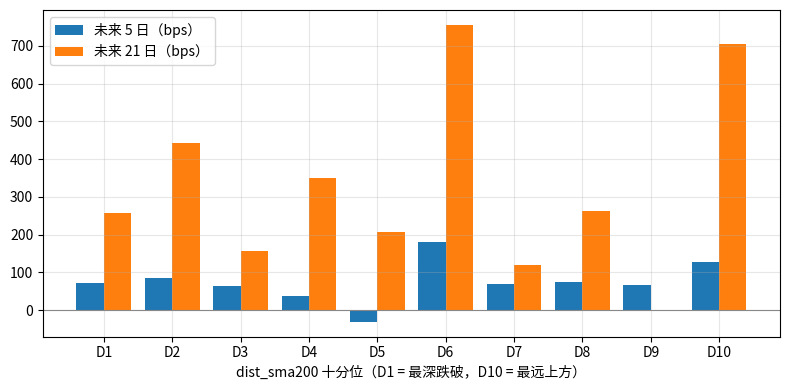

In [10]:
ex = df.loc["2017-01-01":"2025-06-30"].copy()
ex["dist"] = ex["close"] / ex["sma200"] - 1
ex["fwd5"] = ex["close"].shift(-5) / ex["close"] - 1
ex["fwd21"] = ex["close"].shift(-21) / ex["close"] - 1
ex = ex.dropna(subset=["dist", "fwd5", "fwd21"])
q = pd.qcut(ex["dist"], 10, labels=False)
tbl = ex.groupby(q).agg(dist_mean=("dist", "mean"), n=("dist", "size"),
                        fwd5_mean=("fwd5", "mean"), fwd21_mean=("fwd21", "mean"))
tbl.index = [f"D{i+1}" for i in tbl.index]
print(tbl.assign(dist_mean=(tbl["dist_mean"] * 100).round(1),
                 fwd5_mean=(tbl["fwd5_mean"] * 10000).round(0),
                 fwd21_mean=(tbl["fwd21_mean"] * 10000).round(0))
        .rename(columns={"dist_mean": "dist均值%", "fwd5_mean": "未来5日bps", "fwd21_mean": "未来21日bps"}).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(tbl))
ax.bar(x - 0.2, tbl["fwd5_mean"] * 1e4, width=0.4, label="未来 5 日（bps）")
ax.bar(x + 0.2, tbl["fwd21_mean"] * 1e4, width=0.4, label="未来 21 日（bps）")
ax.set_xticks(x, tbl.index)
ax.axhline(0, color="#888", lw=0.8)
ax.set_xlabel("dist_sma200 十分位（D1 = 最深跌破，D10 = 最远上方）")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6. RSI / MACD：定义、经典用法与口径

**RSI(14, Wilder)**：`RSI = 100 − 100/(1+RS)`，`RS = 涨日均幅 / 跌日均幅`（Wilder 平滑 = `ewm(alpha=1/14)`）。
- **中线用法（本节测）**：`RSI > 50` → 多方占优，当动量 regime 门用——等价于"近 14 日平均涨幅 > 平均跌幅"
- 超买超卖用法（>70 / <30 做反转）属于均值回归主题，与"降回撤的趋势门控"无关，这里不测（`cnstock_002594_pattern_discovery` 已扫过反转类）

**MACD(12,26,9)**：`DIF = EMA12 − EMA26`，`DEA = DIF 的 9 日 EMA`，柱 = 2×(DIF−DEA)（国内软件惯例）。
- **金叉死叉（本节测）**：`DIF > DEA` → 持仓，否则空仓——最经典的趋势跟随用法
- **零轴（本节测）**：`DIF > 0` → 持仓——等价于"EMA12 > EMA26"的指数均线排列过滤

**同源性提醒**：RSI 中线、MACD 交叉、SMA50 快线都携带 ~2 周量级的动量信息，可能是同一条信息的三种说法。
先看信号一致率矩阵——两两 >85% 就不是"三个独立证据"，只是一个。

In [11]:
# RSI(14, Wilder)
delta = df["close"].diff()
up, dn = delta.clip(lower=0.0), -delta.clip(upper=0.0)
ru = up.ewm(alpha=1 / 14, adjust=False).mean()
rd = dn.ewm(alpha=1 / 14, adjust=False).mean()
with np.errstate(divide="ignore", invalid="ignore"):
    rs = ru / rd                                  # rd=0（窗口内无下跌）→ rs=inf → RSI=100，符合 Wilder 定义
df["rsi14"] = 100 - 100 / (1 + rs)
# MACD(12,26,9)
ema12 = df["close"].ewm(span=12, adjust=False).mean()
ema26 = df["close"].ewm(span=26, adjust=False).mean()
df["dif"] = ema12 - ema26
df["dea"] = df["dif"].ewm(span=9, adjust=False).mean()
df["macd_hist"] = 2 * (df["dif"] - df["dea"])

sig_rsi = df["rsi14"] > 50                      # NaN > 50 → False，预热期自动空仓
sig_cross = df["dif"] > df["dea"]
sig_zero = df["dif"] > 0
ma200_sig = (df["close"] > df["sma200"]) & df["sma200"].notna()
dual_sig = ma200_sig & (df["close"] > df["sma50"])

sigs = {"close>SMA50": df["close"] > df["sma50"], "RSI14>50": sig_rsi,
        "DIF>DEA": sig_cross, "DIF>0": sig_zero}
agree = pd.DataFrame({a: {b: float((sa == sb).mean()) for b, sb in sigs.items()}
                      for a, sa in sigs.items()})
print("信号一致率（同一交易日两信号同向的比例，全历史）：")
print((agree * 100).round(1).astype(str) + "%")

rules3 = {
    "RSI14>50": backtest_signal(df, sig_rsi),
    "DIF>DEA": backtest_signal(df, sig_cross),
    "DIF>0": backtest_signal(df, sig_zero),
    "SMA200∧RSI": backtest_signal(df, ma200_sig & sig_rsi),
    "dual∧RSI": backtest_signal(df, dual_sig & sig_rsi),
    "dual∧DIF>DEA": backtest_signal(df, dual_sig & sig_cross),
}
for n, r in rules3.items():
    if r.attrs["delay_buys"] or r.attrs["delay_sells"]:
        print(f"{n}：顺延买入 {r.attrs['delay_buys']} / 顺延卖出 {r.attrs['delay_sells']}")

信号一致率（同一交易日两信号同向的比例，全历史）：
            close>SMA50 RSI14>50 DIF>DEA   DIF>0
close>SMA50      100.0%    87.5%   61.5%   91.7%
RSI14>50          87.5%   100.0%   71.7%   84.4%
DIF>DEA           61.5%    71.7%  100.0%   60.4%
DIF>0             91.7%    84.4%   60.4%  100.0%
DIF>DEA：顺延买入 1 / 顺延卖出 0
dual∧DIF>DEA：顺延买入 1 / 顺延卖出 0


In [12]:
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, row_heights=[0.40, 0.17, 0.24, 0.19],
                    subplot_titles=["收盘（log）+ SMA200", "RSI(14)", "MACD(12,26,9)", "仓位条纹（蓝=持仓）"])
fig.add_trace(go.Scatter(x=df.index, y=df["close"], name="close", line=dict(color="#222", width=1.1)), row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df["sma200"], name="SMA200", line=dict(color=SMA_COLOR[200], width=1)), row=1, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df["rsi14"], name="RSI14", line=dict(color="#d62728", width=0.9), showlegend=False), row=2, col=1)
for lvl, dash in [(30, "dot"), (50, "dash"), (70, "dot")]:
    fig.add_hline(y=lvl, line_dash=dash, line_color="#888", line_width=0.8, row=2, col=1)
fig.add_trace(go.Bar(x=df.index, y=df["macd_hist"], name="hist", showlegend=False,
                     marker_color=np.where(df["macd_hist"] >= 0, "#d62728", "#2ca02c")), row=3, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df["dif"], name="DIF", line=dict(color="#1f77b4", width=0.9)), row=3, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df["dea"], name="DEA", line=dict(color="#ff7f0e", width=0.9)), row=3, col=1)
add_state_strip(fig, df.index, rules3["RSI14>50"]["pos"], 4, "RSI>50")
add_state_strip(fig, df.index, rules3["DIF>DEA"]["pos"], 4, "DIF>DEA")
add_state_strip(fig, df.index, rules3["dual∧RSI"]["pos"], 4, "dual∧RSI")
for _, e in episodes.iterrows():
    fig.add_vrect(x0=e["peak"], x1=e["trough"], fillcolor=EPISODE_COLOR, line_width=0)
fig.update_layout(height=900, margin=dict(t=40))
fig.show()

### 6.1 指标规则分段表

六条规则：三条单独指标门（RSI 中线 / MACD 交叉 / MACD 零轴）+ 三条共振门（趋势信号 ∧ 动量确认）。
参照行（buy&hold / gate SMA200 / dual 200+50）与 §3/§4 同口径重复列出，方便直接对比。**同样不出判定**。

In [13]:
ref_rules = {"gate SMA200": r_gate200, "dual 200+50": r_dual}
tables3 = {}
for seg_name, (lo, hi) in SEGMENTS.items():
    base = summarize(seg_slice(BH["idx_net"], lo, hi))
    rows = {"buy&hold": {"总收益": base["total_return"], "年化": base["ann_return"],
                        "MDD": base["max_drawdown"], "MDD比": 1.0, "收益比": 1.0,
                        "Calmar": base["calmar"], "Sharpe": base["sharpe"], "切换/年": 0.0, "持仓占比": 1.0}}
    for name, r in {**ref_rules, **rules3}.items():
        rows[name] = seg_metrics(r, lo, hi, base)
    t = pd.DataFrame(rows).T
    tables3[seg_name] = t
    print(f"\n=== {seg_name}（{lo} → {hi or '今'}）===")
    display(t.style.format({"总收益": "{:+.1%}", "年化": "{:+.1%}", "MDD": "{:.1%}",
                            "MDD比": "{:.2f}", "收益比": "{:.2f}", "Calmar": "{:.2f}",
                            "Sharpe": "{:.2f}", "切换/年": "{:.1f}", "持仓占比": "{:.0%}"}))


=== 全段(2012-07→)（2012-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+2178.3%,+24.7%,-61.7%,1.00,1.00,0.40,0.68,0.0,100%
gate SMA200,+416.2%,+12.3%,-78.6%,1.27,0.19,0.16,0.48,8.0,55%
dual 200+50,+590.1%,+14.6%,-63.0%,1.02,0.27,0.23,0.55,11.7,38%
RSI14>50,+717.8%,+16.0%,-61.1%,0.99,0.33,0.26,0.57,26.9,50%
DIF>DEA,+1136.4%,+19.4%,-62.0%,1.00,0.52,0.31,0.65,18.1,51%
DIF>0,+766.1%,+16.4%,-64.8%,1.05,0.35,0.25,0.58,8.0,50%
SMA200∧RSI,+694.5%,+15.7%,-53.7%,0.87,0.32,0.29,0.59,17.5,37%
dual∧RSI,+462.8%,+13.0%,-65.2%,1.06,0.21,0.20,0.52,15.8,34%
dual∧DIF>DEA,+588.1%,+14.6%,-61.5%,1.00,0.27,0.24,0.61,12.7,23%



=== pre_val（2017-01-01 → 2021-12-31）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+537.2%,+45.0%,-55.6%,1.00,1.00,0.81,0.99,0.0,100%
gate SMA200,+268.6%,+29.9%,-50.3%,0.90,0.50,0.60,0.81,5.4,60%
dual 200+50,+356.6%,+35.6%,-48.0%,0.86,0.66,0.74,0.96,10.0,45%
RSI14>50,+325.6%,+33.7%,-51.5%,0.93,0.61,0.66,0.90,22.5,54%
DIF>DEA,+338.0%,+34.5%,-62.0%,1.12,0.63,0.56,0.96,16.1,53%
DIF>0,+441.5%,+40.3%,-37.0%,0.67,0.82,1.09,1.01,6.4,55%
SMA200∧RSI,+318.8%,+33.3%,-47.3%,0.85,0.59,0.70,0.93,15.2,41%
dual∧RSI,+208.0%,+25.3%,-60.4%,1.09,0.39,0.42,0.78,16.1,39%
dual∧DIF>DEA,+258.6%,+29.2%,-54.8%,0.99,0.48,0.53,0.94,12.0,28%



=== val（2022-01-01 → 2025-06-30）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+24.8%,+6.6%,-53.7%,1.00,1.00,0.12,0.36,0.0,100%
gate SMA200,-4.1%,-1.2%,-40.8%,0.76,-0.16,-0.03,0.08,7.0,49%
dual 200+50,+15.5%,+4.3%,-29.0%,0.54,0.62,0.15,0.30,10.4,32%
RSI14>50,-12.4%,-3.8%,-47.7%,0.89,-0.50,-0.08,-0.03,32.5,48%
DIF>DEA,-15.6%,-4.8%,-48.8%,0.91,-0.63,-0.10,-0.05,20.9,52%
DIF>0,+26.9%,+7.1%,-30.5%,0.57,1.08,0.23,0.40,8.7,47%
SMA200∧RSI,+17.0%,+4.7%,-35.1%,0.65,0.69,0.13,0.32,16.8,31%
dual∧RSI,+24.5%,+6.6%,-31.8%,0.59,0.99,0.21,0.41,13.3,28%
dual∧DIF>DEA,+36.6%,+9.5%,-23.0%,0.43,1.47,0.41,0.59,10.4,18%



=== test（2025-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,-24.8%,-20.6%,-31.4%,1.00,1.00,-0.66,-0.71,0.0,100%
gate SMA200,-23.8%,-19.7%,-24.5%,0.78,nan,-0.80,-1.73,18.6,17%
dual 200+50,-16.4%,-13.5%,-18.8%,0.60,nan,-0.72,-1.27,12.9,10%
RSI14>50,-27.9%,-23.2%,-28.0%,0.89,nan,-0.83,-1.52,30.7,30%
DIF>DEA,-14.5%,-11.9%,-20.5%,0.65,nan,-0.58,-0.53,17.0,43%
DIF>0,-23.5%,-19.5%,-25.1%,0.80,nan,-0.78,-1.23,11.3,30%
SMA200∧RSI,-20.3%,-16.7%,-20.4%,0.65,nan,-0.82,-1.56,16.2,12%
dual∧RSI,-16.4%,-13.5%,-18.8%,0.60,nan,-0.72,-1.27,12.9,10%
dual∧DIF>DEA,-10.4%,-8.5%,-13.0%,0.41,nan,-0.66,-0.91,8.1,7%


### 6.2 episode 内回撤对照（含指标规则）

同 §5 的最深 3 段。看点：指标规则相对双均线，首次退出是否更早（距 peak 跌幅更小）、episode 内 MDD 是否更浅、再入场错过的修复更多还是更少。

In [14]:
for i, e in deepest3.iterrows():
    lab = f"{e['peak'].date()} → {e['trough'].date()}（{e['depth']:.0%}）"
    d = {"buy&hold": {"episode内MDD": e["depth"], "首次退出": "—", "退出时距peak跌幅": np.nan, "末次再入场": "—"}}
    for name, r in {**ref_rules, **rules3}.items():
        d[name] = rule_episode_stats(r, e)
    t = pd.DataFrame(d).T
    t["episode内MDD"] = t["episode内MDD"].map(_fmt_pct)
    t["退出时距peak跌幅"] = t["退出时距peak跌幅"].map(_fmt_pct)
    print(f"\n=== episode {lab} ===")
    print(t.to_string())


=== episode 2011-07-07 → 2012-09-26（-81%） ===
             episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold          -81.2%           —          —           —
gate SMA200       -37.5%  2012-05-15     -38.9%  2013-01-04
dual 200+50       -37.0%  2013-03-14     -42.8%  2013-04-25
RSI14>50          -34.5%  2011-08-25     -31.6%  2013-04-22
DIF>DEA           -46.8%  2011-07-18      -6.5%  2013-04-19
DIF>0             -56.7%  2011-08-09     -29.6%  2013-04-25
SMA200∧RSI        -21.0%  2013-03-08     -41.5%  2013-04-22
dual∧RSI          -27.7%  2013-03-08     -41.5%  2013-04-25
dual∧DIF>DEA      -19.8%  2013-01-25     -46.1%  2013-04-25

=== episode 2015-06-04 → 2018-08-06（-62%） ===
             episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold          -61.7%           —          —           —
gate SMA200       -78.6%  2015-06-30     -38.3%  2020-03-26
dual 200+50       -63.0%  2015-06-23     -27.6%  2020-05-27
RSI14>50          -61.1%  2015-06-18     -21.5%  2020-06-02
DIF>DE

## 7. 观察记录（看完图在这里写）

> 规则（与 crypto §6 相同）：先写**方向 + 规则 + 时间尺度 + 预期在哪个 regime 起作用**，再去跑正式回测。写下来的东西不能因为回测结果改。
> ⚠️ 本 notebook 已展示 test 段（2025-07→）：在这里看完图才提的假设，**test 段不再是无偏留出**，
> 要么承认它是描述性结论，要么用 2026 之后的新数据 / 其它股票（兄弟资产检验）做首次验证。

| # | 观察到的现象（哪段 episode / 哪张图） | 假设（方向先写死） | 规则形式 | 时间尺度 | 预期起作用的 regime | 登记人 / 日期 |
|---|---|---|---|---|---|---|
| 1 | 002594 §6：dual∧DIF>DEA val/test MDD 比 0.43/0.41、三段 episode 最浅；pre_val 无改善 | dual∧DIF>DEA 相比 dual 200+50 同段 MDD 更浅且切换不增（增量来自 61.5% 一致率的更快退出） | close>SMA200 ∧ close>SMA50 ∧ DIF>DEA | 日线 | 趋势恶化初期的退出 | Claude / 2026-09-30 |
| 2 |  |  |  |  |  |  |
| 3 |  |  |  |  |  |  |

**回看时的自检问题**：
1. 单均线网格里，MDD比 < 2/3 的 N 是否聚成平台（邻域都有效），还是孤点？（BTC 的 gate 长度是平台、退出长度不是）
2. 双均线相对单均线，回撤的进一步压缩来自哪一段 episode？是机制（每次都更早离场）还是单次运气？
3. 切换/年 × 0.28% 的成本，和收益比的损失对得上吗？对不上的部分（空仓期机会成本）在哪个 regime 发生？
4. RSI / MACD 与 SMA50 的信号一致率是多少？共振门（如 dual∧RSI）相对双均线多压下去的回撤，是真增量还是同一个信号的重复计数？

## 8. 兄弟股票验证：300866 安克创新（H-BYD-1，2026-09-30 登记）

> **先登记，后跑数**（登记原文同步在 `tasks/todo.md`，本节代码首次执行前未看任何 300866 结果）：
> - **规则**：`target = 1 iff close > SMA200 且 close > SMA50 且 DIF(12,26) > DEA(9)`，否则 0；T+1 生效、§1.2 成本、创业板 20% 涨跌停顺延
> - **方向**（从 002594 §6 外推）：dual∧DIF>DEA 相比 dual 200+50，**同段 MDD 更浅且切换不增**
> - **判定**：PASS = val、test 两段 dual∧DIF>DEA 的 MDD 都 ≤ dual 200+50 同段 MDD，且 val 总收益 ≥ 80% × dual，且 val 切换/年 ≤ dual + 5；否则 FAIL
> - **预判（写死）**：PASS，但幅度小于 002594（20cm 波动，交叉信号打脸更多）
>
> 300866 于 2020-08-24 上市（注册制首日，全程 20% 阈值，无停牌）；SMA200 预热约 2021-06 结束。
> 段 = pre_val 2021-07→2021-12（仅半年，仅供参考）/ val 2022→2025-06 / test 2025-07→。

In [15]:
def load_stock(code: str, limit_thr: float) -> pd.DataFrame:
    """与 §0/§6 完全同口径的单股日线管线（SMA + RSI + MACD + 涨跌停标记）。"""
    d = read_cnstock_kline_day(code).rename(columns={
        "open_price": "open", "high_price": "high", "low_price": "low", "close_price": "close"}).copy()
    ts = pd.to_datetime(d["trade_time"])
    if ts.dt.tz is None:
        ts = ts.dt.tz_localize("UTC")
    d["date"] = ts.dt.tz_convert("Asia/Shanghai").dt.tz_localize(None).dt.normalize()
    d = d.set_index("date").sort_index()
    assert d.index.is_unique and d.index.is_monotonic_increasing
    for n in SMA_LIST:
        d[f"sma{n}"] = d["close"].rolling(n).mean()
    d["ret"] = d["close"].pct_change()
    d["prev_close"] = d["close"].shift(1)
    d["limit_up_open"] = (d["open"] / d["prev_close"] - 1) >= limit_thr
    d["limit_down_open"] = (d["open"] / d["prev_close"] - 1) <= -limit_thr
    delta = d["close"].diff()
    up, dn = delta.clip(lower=0.0), -delta.clip(upper=0.0)
    ru = up.ewm(alpha=1 / 14, adjust=False).mean()
    rd = dn.ewm(alpha=1 / 14, adjust=False).mean()
    with np.errstate(divide="ignore", invalid="ignore"):
        rs = ru / rd
    d["rsi14"] = 100 - 100 / (1 + rs)
    e12 = d["close"].ewm(span=12, adjust=False).mean()
    e26 = d["close"].ewm(span=26, adjust=False).mean()
    d["dif"] = e12 - e26
    d["dea"] = d["dif"].ewm(span=9, adjust=False).mean()
    return d


def build_rule_set(d: pd.DataFrame) -> dict:
    ma200 = (d["close"] > d["sma200"]) & d["sma200"].notna()
    dual = ma200 & (d["close"] > d["sma50"])
    return {"gate SMA200": backtest_signal(d, ma200),
            "dual 200+50": backtest_signal(d, dual),
            "RSI14>50": backtest_signal(d, d["rsi14"] > 50),
            "DIF>DEA": backtest_signal(d, d["dif"] > d["dea"]),
            "DIF>0": backtest_signal(d, d["dif"] > 0),
            "SMA200∧RSI": backtest_signal(d, ma200 & (d["rsi14"] > 50)),
            "dual∧RSI": backtest_signal(d, dual & (d["rsi14"] > 50)),
            "dual∧DIF>DEA": backtest_signal(d, dual & (d["dif"] > d["dea"]))}


def segment_tables(d: pd.DataFrame, rules: dict, segments: dict) -> dict:
    bh = bh_frame(d["ret"])
    out = {}
    for seg_name, (lo, hi) in segments.items():
        base = summarize(seg_slice(bh["idx_net"], lo, hi))
        rows = {"buy&hold": {"总收益": base["total_return"], "年化": base["ann_return"],
                            "MDD": base["max_drawdown"], "MDD比": 1.0, "收益比": 1.0,
                            "Calmar": base["calmar"], "Sharpe": base["sharpe"], "切换/年": 0.0, "持仓占比": 1.0}}
        for name, r in rules.items():
            rows[name] = seg_metrics(r, lo, hi, base)
        t = pd.DataFrame(rows).T
        out[seg_name] = t
        print(f"\n=== {seg_name}（{lo} → {hi or '今'}）===")
        display(t.style.format({"总收益": "{:+.1%}", "年化": "{:+.1%}", "MDD": "{:.1%}",
                                "MDD比": "{:.2f}", "收益比": "{:.2f}", "Calmar": "{:.2f}",
                                "Sharpe": "{:.2f}", "切换/年": "{:.1f}", "持仓占比": "{:.0%}"}))
    return out

d866 = load_stock("300866", 0.198)          # 创业板注册制起 20%
print(f"300866 日线：{d866.index[0].date()} → {d866.index[-1].date()}，{len(d866)} 个交易日；"
      f"停牌 {int(d866['suspension'].sum())} 天；"
      f"涨停开盘 {int(d866['limit_up_open'].sum())} / 跌停开盘 {int(d866['limit_down_open'].sum())} 天")
SEG866 = {"全段(2021-07→)": ("2021-07-01", None),
          "pre_val(仅半年)": ("2021-07-01", "2021-12-31"),
          "val": ("2022-01-01", "2025-06-30"),
          "test": ("2025-07-01", None)}
rules866 = build_rule_set(d866)
for n, r in rules866.items():
    if r.attrs["delay_buys"] or r.attrs["delay_sells"]:
        print(f"{n}：顺延买入 {r.attrs['delay_buys']} / 顺延卖出 {r.attrs['delay_sells']}")
tables866 = segment_tables(d866, rules866, SEG866)

300866 日线：2020-08-24 → 2026-09-29，1476 个交易日；停牌 0 天；涨停开盘 1 / 跌停开盘 1 天
RSI14>50：顺延买入 0 / 顺延卖出 1
DIF>DEA：顺延买入 0 / 顺延卖出 1
SMA200∧RSI：顺延买入 0 / 顺延卖出 1

=== 全段(2021-07→)（2021-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+3.7%,+0.7%,-72.4%,1.00,1.00,0.01,0.26,0.0,100%
gate SMA200,-15.6%,-3.2%,-46.3%,0.64,-4.19,-0.07,0.06,10.0,52%
dual 200+50,+43.6%,+7.2%,-33.5%,0.46,11.71,0.21,0.39,9.8,42%
RSI14>50,+15.7%,+2.8%,-44.3%,0.61,4.22,0.06,0.26,24.4,52%
DIF>DEA,-3.5%,-0.7%,-51.9%,0.72,-0.95,-0.01,0.17,17.5,49%
DIF>0,+35.4%,+6.0%,-40.9%,0.57,9.53,0.15,0.34,6.5,54%
SMA200∧RSI,-4.4%,-0.9%,-41.0%,0.57,-1.17,-0.02,0.11,16.3,38%
dual∧RSI,+22.4%,+4.0%,-40.4%,0.56,6.02,0.10,0.28,14.8,38%
dual∧DIF>DEA,-13.9%,-2.8%,-41.6%,0.57,-3.74,-0.07,-0.03,15.6,24%



=== pre_val(仅半年)（2021-07-01 → 2021-12-31）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,-39.3%,-62.5%,-47.4%,1.00,1.00,-1.32,-1.09,0.0,100%
gate SMA200,-5.6%,-10.7%,-5.6%,0.12,nan,-1.91,-1.46,2.0,2%
dual 200+50,-5.6%,-10.7%,-5.6%,0.12,nan,-1.91,-1.46,2.0,2%
RSI14>50,-30.0%,-50.4%,-31.0%,0.65,nan,-1.62,-1.41,29.5,28%
DIF>DEA,-13.7%,-25.1%,-33.5%,0.71,nan,-0.75,-0.21,13.8,48%
DIF>0,-29.4%,-49.7%,-29.4%,0.62,nan,-1.69,-2.50,3.9,26%
SMA200∧RSI,-5.6%,-10.7%,-5.6%,0.12,nan,-1.91,-1.46,2.0,2%
dual∧RSI,-5.6%,-10.7%,-5.6%,0.12,nan,-1.91,-1.46,2.0,2%
dual∧DIF>DEA,-5.6%,-10.7%,-5.6%,0.12,nan,-1.91,-1.46,2.0,2%



=== val（2022-01-01 → 2025-06-30）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+54.9%,+13.5%,-54.5%,1.00,1.00,0.25,0.50,0.0,100%
gate SMA200,+16.8%,+4.6%,-41.1%,0.75,0.31,0.11,0.30,10.1,56%
dual 200+50,+66.0%,+15.8%,-29.0%,0.53,1.20,0.55,0.66,10.1,45%
RSI14>50,+78.6%,+18.3%,-35.9%,0.66,1.43,0.51,0.64,21.2,56%
DIF>DEA,+4.3%,+1.2%,-48.3%,0.89,0.08,0.03,0.22,17.4,49%
DIF>0,+86.2%,+19.7%,-37.8%,0.69,1.57,0.52,0.70,7.0,57%
SMA200∧RSI,+30.9%,+8.1%,-35.9%,0.66,0.56,0.23,0.41,14.8,42%
dual∧RSI,+65.7%,+15.8%,-28.7%,0.53,1.20,0.55,0.67,13.0,41%
dual∧DIF>DEA,+5.2%,+1.5%,-32.5%,0.60,0.09,0.05,0.18,16.2,27%



=== test（2025-07-01 → 今）===


,总收益,年化,MDD,MDD比,收益比,Calmar,Sharpe,切换/年,持仓占比
buy&hold,+11.2%,+9.0%,-37.0%,1.00,1.00,0.24,0.41,0.0,100%
gate SMA200,-22.9%,-19.0%,-46.3%,1.25,-2.05,-0.41,-0.47,13.0,61%
dual 200+50,-7.7%,-6.3%,-33.5%,0.91,-0.69,-0.19,-0.08,12.2,49%
RSI14>50,-6.8%,-5.6%,-35.9%,0.97,-0.61,-0.16,-0.02,31.6,51%
DIF>DEA,+7.1%,+5.7%,-16.2%,0.44,0.64,0.35,0.33,19.5,48%
DIF>0,+4.0%,+3.2%,-31.6%,0.85,0.36,0.10,0.26,6.5,55%
SMA200∧RSI,-22.1%,-18.3%,-41.0%,1.11,-1.97,-0.45,-0.59,26.8,43%
dual∧RSI,-21.2%,-17.6%,-40.4%,1.09,-1.89,-0.44,-0.58,25.1,42%
dual∧DIF>DEA,-13.3%,-11.0%,-21.7%,0.59,-1.19,-0.51,-0.42,19.5,28%


### 8.1 判定（按登记口径逐条核对）

In [16]:
agree866 = ((d866["close"] > d866["sma50"]) == (d866["dif"] > d866["dea"])).mean()
print(f"信号一致率 close>SMA50 vs DIF>DEA：300866 = {agree866:.1%}（002594 = 61.5%；越低越说明是独立信息）\n")

dv, mv = tables866["val"].loc["dual 200+50"], tables866["val"].loc["dual∧DIF>DEA"]
ds, ms = tables866["test"].loc["dual 200+50"], tables866["test"].loc["dual∧DIF>DEA"]
checks = {
    "val MDD 不更深":  (abs(mv["MDD"]) <= abs(dv["MDD"]),        f"{mv['MDD']:.1%} vs dual {dv['MDD']:.1%}"),
    "test MDD 不更深": (abs(ms["MDD"]) <= abs(ds["MDD"]),        f"{ms['MDD']:.1%} vs dual {ds['MDD']:.1%}"),
    "val 收益 ≥ 80%×dual": (mv["总收益"] >= 0.8 * dv["总收益"],  f"{mv['总收益']:+.1%} vs dual {dv['总收益']:+.1%}"),
    "val 切换 ≤ dual+5":   (mv["切换/年"] <= dv["切换/年"] + 5,  f"{mv['切换/年']:.1f} vs dual {dv['切换/年']:.1f}"),
}
for k, (ok, detail) in checks.items():
    print(f"  [{'通过' if ok else '未过'}] {k}（{detail}）")
print(f"\nH-BYD-1 判定：{'PASS' if all(ok for ok, _ in checks.values()) else 'FAIL'}")

信号一致率 close>SMA50 vs DIF>DEA：300866 = 61.0%（002594 = 61.5%；越低越说明是独立信息）

  [未过] val MDD 不更深（-32.5% vs dual -29.0%）
  [通过] test MDD 不更深（-21.7% vs dual -33.5%）
  [未过] val 收益 ≥ 80%×dual（+5.2% vs dual +66.0%）
  [未过] val 切换 ≤ dual+5（16.2 vs dual 10.1）

H-BYD-1 判定：FAIL


### 8.2 净值与 episode（300866 自己的最深回撤）

In [17]:
bh866 = bh_frame(d866["ret"])
ep866 = drawdown_episodes(bh866["idx_net"], top=3)
print(ep866.assign(depth=(ep866["depth"] * 100).round(1)).to_string(index=False))

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3],
                    subplot_titles=["300866 净值（log）", "仓位条纹（蓝=持仓）"])
fig.add_trace(go.Scatter(x=d866.index, y=bh866["idx_net"], name="buy&hold", line=dict(color="#222", width=1.2)), row=1, col=1)
fig.add_trace(go.Scatter(x=d866.index, y=rules866["dual 200+50"]["idx_net"], name="dual 200+50",
                         line=dict(color="#ff7f0e", width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=d866.index, y=rules866["dual∧DIF>DEA"]["idx_net"], name="dual∧DIF>DEA",
                         line=dict(color="#2ca02c", width=1)), row=1, col=1)
fig.update_yaxes(type="log", row=1, col=1)
add_state_strip(fig, d866.index, rules866["dual 200+50"]["pos"], 2, "dual")
add_state_strip(fig, d866.index, rules866["dual∧DIF>DEA"]["pos"], 2, "dual∧MACD")
for _, e in ep866.iterrows():
    fig.add_vrect(x0=e["peak"], x1=e["trough"], fillcolor=EPISODE_COLOR, line_width=0)
fig.update_layout(height=560, margin=dict(t=40))
fig.show()

for i, e in ep866.iterrows():
    lab = f"{e['peak'].date()} → {e['trough'].date()}（{e['depth']:.0%}）"
    dct = {"buy&hold": {"episode内MDD": e["depth"], "首次退出": "—", "退出时距peak跌幅": np.nan, "末次再入场": "—"}}
    for name in ["dual 200+50", "dual∧DIF>DEA"]:
        dct[name] = rule_episode_stats(rules866[name], e, d866)
    t = pd.DataFrame(dct).T
    t["episode内MDD"] = t["episode内MDD"].map(_fmt_pct)
    t["退出时距peak跌幅"] = t["退出时距peak跌幅"].map(_fmt_pct)
    print(f"\n=== episode {lab} ===")
    print(t.to_string())

      peak     trough        end  depth  自然日
2020-08-25 2020-09-10 2020-11-02  -29.6   69
2020-11-09 2022-04-26 2025-08-18  -77.0 1743
2025-08-18 2026-03-09 2026-09-29  -37.0  407



=== episode 2020-08-25 → 2020-09-10（-30%） ===
             episode内MDD 首次退出 退出时距peak跌幅 末次再入场
buy&hold          -29.6%    —          —     —
dual 200+50         0.0%    —          —     —
dual∧DIF>DEA        0.0%    —          —     —

=== episode 2020-11-09 → 2022-04-26（-77%） ===
             episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold          -77.0%           —          —           —
dual 200+50       -29.0%  2021-07-05     -24.6%  2025-05-13
dual∧DIF>DEA      -34.7%  2021-07-05     -24.6%  2025-08-08

=== episode 2025-08-18 → 2026-03-09（-37%） ===
             episode内MDD        首次退出 退出时距peak跌幅       末次再入场
buy&hold          -37.0%           —          —           —
dual 200+50       -33.5%  2025-09-17      -9.0%  2026-07-28
dual∧DIF>DEA      -21.7%  2025-08-27      -8.3%  2026-08-27
